# 01 · Explore the sources

Goal: check the real granularity of each source (geography, breakdowns, time span,
gaps) before fixing the star schema.

Run the downloads first:

```bash
python -m etl.download_ine
python -m etl.download_airports
python -m etl.download_ibestat
```

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from etl.config import AIRPORT_RAW, IBESTAT_DATASETS, IBESTAT_RAW, INE_RAW, INE_TABLES
from etl.eurostat_parse import load_jsonstat
from etl.ibestat_parse import load_metamac
from etl.ine_parse import balearic_only, load_ine_json

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## 1. INE tables: which dimensions does each one carry?

In [2]:
tables = {name: load_ine_json(INE_RAW / f'{name}.json') for name in INE_TABLES}
BASE_COLS = {'series_code', 'series_name', 'unit', 'year', 'month', 'period', 'data_status', 'value'}
summary = []
for name, df in tables.items():
    bal = balearic_only(df)
    summary.append({
        'table': name,
        'rows (Spain)': len(df),
        'rows (Balearics)': len(bal),
        'first year (Balearics)': bal.year.min(),
        'last period': f"{bal.year.max()}-{bal.loc[bal.year == bal.year.max(), 'month'].max():02.0f}" if len(bal) else None,
        'dimensions': [c for c in df.columns if c not in BASE_COLS],
    })
pd.DataFrame(summary)

,table,rows (Spain),rows (Balearics),first year (Balearics),last period,dimensions
0,eoh_zone_travellers_nights,31624,3172,2010.0,2026-09,"[Concepto turístico, TIPO DE CATEGORIA, ZONAS ..."
1,eoh_zone_supply_occupancy,53081,5321,2010.0,2026-09,"[Concepto turístico, TIPO DE CATEGORIA, ZONAS ..."
2,eoh_province_travellers_nights,84410,2412,2010.0,2026-09,"[Totales Territoriales, Concepto turístico, TI..."
3,eoh_country_travellers_nights,12134,0,NaN,NaN,"[Totales Territoriales, Concepto turístico, TI..."
4,irsh_zone_adr,5204,552,2021.0,2026-09,"[ZONAS TURÍSTICAS, Concepto turístico, TIPO DE..."
5,irsh_zone_revpar,5204,552,2021.0,2026-09,"[ZONAS TURÍSTICAS, Concepto turístico, TIPO DE..."


The country table (`eoh_country_travellers_nights`, INE 2038) has **no Balearic rows**:
it is national only, as expected. ADR and RevPAR (IRSH) start in **2021**.

## 2. Balearic zones and residence breakdown in the EOH

In [3]:
demand = balearic_only(tables['eoh_zone_travellers_nights'])
for col in ['Concepto turístico', 'ZONAS TURÍSTICAS', 'RESIDENCIA/ORIGEN', 'TIPO DE CATEGORIA']:
    print(f'{col:20s} -> {sorted(demand[col].dropna().unique())}')

Concepto turístico   -> ['Pernoctaciones', 'Viajero']
ZONAS TURÍSTICAS     -> ['Baleares (Illes): Isla De Mallorca', 'Baleares (Illes): Isla De Menorca', 'Baleares (Illes): Islas De Ibiza-Formentera', 'Baleares (Illes): Palma - Calvía']
RESIDENCIA/ORIGEN    -> ['Residentes en España', 'Residentes en el Extranjero']
TIPO DE CATEGORIA    -> ['Total categorías']


## 3. Does *Isla de Mallorca* include *Palma - Calvià*?

If the three island zones add up to the province total (INE 2074), then
*Isla de Mallorca* already contains *Palma - Calvià*, which is a sub-zone of it.
If instead we need all four zones to reach the province total, they are disjoint.

In [4]:
nights = demand[demand['Concepto turístico'] == 'Pernoctaciones']
zones = nights.groupby(['year', 'month', 'ZONAS TURÍSTICAS']).value.sum(min_count=1).unstack()
zones.columns = ['mallorca', 'menorca', 'ibiza_formentera', 'palma_calvia']

province = balearic_only(tables['eoh_province_travellers_nights'])
province = (province[province.series_name == 'Baleares (Illes). Pernoctaciones. Total.']
            .set_index(['year', 'month']).value.rename('province'))

check = zones.join(province)
island_sum = check[['mallorca', 'menorca', 'ibiza_formentera']].sum(axis=1, min_count=1)
check['ratio_3_islands'] = island_sum / check.province
check['ratio_4_zones'] = (island_sum + check.palma_calvia) / check.province
complete = check.dropna(subset=['mallorca', 'menorca', 'ibiza_formentera'])
complete[['ratio_3_islands', 'ratio_4_zones']].describe().round(4)

,ratio_3_islands,ratio_4_zones
count,149.0,149.0000
mean,1.0,1.4008
std,0.0,0.1547
min,1.0,1.2645
25%,1.0,1.2868
50%,1.0,1.3078
75%,1.0,1.5116
max,1.0,1.7721


**Answer: yes, it includes it.** In every month where all three islands are
published, Mallorca + Menorca + Ibiza-Formentera equals the province total
(ratio 1.000), while adding Palma - Calvià overshoots by roughly 30-80 %.

So *Palma - Calvià* is a **sub-zone of Mallorca**, not a sibling. To keep the
demand fact additive, the warehouse stores *Palma - Calvià* and a derived
*Rest of Mallorca* (= Isla de Mallorca − Palma - Calvià) as separate leaves.

## 4. Gaps: statistical suppression in winter

When the three islands do **not** add up, it is because a small island is missing
(INE does not publish cells with too few open hotels).

In [5]:
gaps = check[check.ratio_3_islands < 0.995][['mallorca', 'menorca', 'ibiza_formentera', 'province', 'ratio_3_islands']]
print(f'{len(gaps)} of {len(check)} months have suppressed island cells')
gaps.head(10)

49 of 201 months have suppressed island cells


mallorca  menorca  ibiza_formentera   province  ratio_3_islands
year month                                                                  
2010 11      407199.0      NaN           28804.0   469049.0         0.929547
     12      224009.0      NaN               NaN   241385.0         0.928015
2011 1       277645.0      NaN               NaN   293934.0         0.944583
     2       598496.0      NaN           45718.0   668742.0         0.963322
     3      1217610.0      NaN           73732.0  1329533.0         0.971275
     11      389723.0      NaN           32555.0   464802.0         0.908512
     12      213617.0      NaN               NaN   227455.0         0.939162
2012 1       277460.0      NaN            9628.0   291157.0         0.986025
     2       626384.0      NaN           42758.0   690910.0         0.968494
     3      1246035.0      NaN           68853.0  1352675.0         0.972065

In [6]:
missing_by_month = (zones[['menorca', 'ibiza_formentera']].isna()
                    .groupby(level='month').mean().round(2))
missing_by_month.T

month,1,2,3,4,5,6,7,8,9,10,11,12
menorca,0.71,0.47,0.24,0.0,0.06,0.06,0.0,0.0,0.0,0.0,0.62,0.88
ibiza_formentera,0.41,0.06,0.00,0.0,0.06,0.06,0.0,0.0,0.0,0.0,0.38,0.75


Gaps are concentrated in November-February, mostly Menorca. The province total
is always published, so the warehouse adds an **Unallocated** destination
(= province − islands published) and the monthly Balearic totals stay exact.
In April-May 2020 hotels were closed by the COVID-19 lockdown, so zero values
there are real.

## 5. Seasonality at a glance

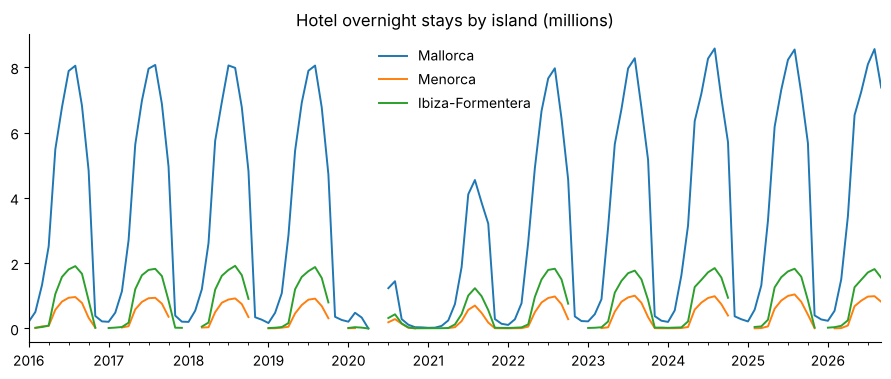

In [7]:
ts = zones[['mallorca', 'menorca', 'ibiza_formentera']].copy()
ts.index = pd.to_datetime(ts.index.map(lambda ym: f'{ym[0]}-{ym[1]:02d}-01'))
ax = (ts['2016':] / 1e6).plot(lw=1.4)
ax.set_title('Hotel overnight stays by island (millions)')
ax.set_xlabel(''); ax.legend(['Mallorca', 'Menorca', 'Ibiza-Formentera'], frameon=False)
plt.show()

In [8]:
# Share of the year's overnight stays that fall in July-August (2023-2025)
recent = zones.loc[2023:2025, ['mallorca', 'menorca', 'ibiza_formentera']]
summer = recent[recent.index.get_level_values('month').isin([7, 8])].sum()
(summer / recent.sum()).round(3).rename('Jul+Aug share')

mallorca            0.345
menorca             0.428
ibiza_formentera    0.391
Name: Jul+Aug share, dtype: float64

## 6. Hotel performance: supply, occupancy, ADR, RevPAR

These come without a residence split, which is why they live in a second fact
table. Rates cannot be summed, so the plan is to store their **additive
components** and recompute the ratios at query time:

| Component | Formula |
|---|---|
| available bed-nights | bed places × days in month |
| available room-nights | rooms × days in month |
| occupied room-nights | room occupancy rate × available room-nights |
| room revenue | RevPAR × available room-nights |
| rooms sold (IRSH) | room revenue / ADR |

This also lets us **derive the rates for Rest of Mallorca** by subtraction.
A quick consistency check: RevPAR / ADR should be close to the EOH room occupancy rate.

In [9]:
perf = balearic_only(tables['eoh_zone_supply_occupancy'])
print(sorted(perf['Concepto turístico'].unique()))

def irsh(name):
    df = balearic_only(tables[name])
    return df[df.series_name.str.contains('Dato')].groupby(['year', 'month', 'ZONAS TURÍSTICAS']).value.first()

adr, revpar = irsh('irsh_zone_adr'), irsh('irsh_zone_revpar')
occ_rooms = (perf[perf['Concepto turístico'] == 'Grado de ocupación por habitaciones']
             .groupby(['year', 'month', 'ZONAS TURÍSTICAS']).value.first())
cmp = pd.DataFrame({'adr': adr, 'revpar': revpar, 'occ_rooms_pct': occ_rooms}).dropna()
cmp['implied_occ_pct'] = 100 * cmp.revpar / cmp.adr
cmp['diff_pp'] = cmp.implied_occ_pct - cmp.occ_rooms_pct
cmp.groupby(level='ZONAS TURÍSTICAS').diff_pp.describe().round(2)

['Grado de ocupación por habitaciones', 'Grado de ocupación por plazas', 'Grado de ocupación por plazas en fin de semana', 'Número de establecimientos abiertos estimados', 'Número de habitaciones estimadas', 'Número de plazas estimadas', 'Personal empleado']


,count,mean,std,min,25%,50%,75%,max
ZONAS TURÍSTICAS,,,,,,,,
Baleares (Illes): Isla De Mallorca,69.0,-0.73,1.90,-8.46,-1.48,-0.38,0.25,3.62
Baleares (Illes): Isla De Menorca,57.0,-0.22,2.56,-6.28,-1.85,-0.02,0.95,6.87
Baleares (Illes): Islas De Ibiza-Formentera,63.0,-0.64,3.48,-17.83,-2.12,0.05,1.09,6.59
Baleares (Illes): Palma - Calvía,69.0,-0.40,2.04,-9.29,-1.40,-0.00,0.62,3.87


RevPAR / ADR matches the EOH room occupancy rate within about 1 percentage point
(median), so the two surveys are consistent enough to combine room revenue and
rooms sold with the EOH supply figures.

## 7. Airports (Eurostat `avia_paoa`, reported by AENA)

In [10]:
air = load_jsonstat(AIRPORT_RAW / 'avia_paoa.json')
print(air.groupby(['tra_meas', 'tra_cov']).size())
annual = (air[(air.tra_meas == 'PAS_CRD') & (air.tra_cov == 'TOTAL')]
          .assign(year=lambda d: d.time.str[:4])
          .pivot_table(index='year', columns='rep_airp', values='value', aggfunc='sum') / 1e6)
annual.tail(6).round(2)

tra_meas     tra_cov
PAS_CRD      INTL       594
             NAT        594
             TOTAL      594
PAS_CRD_ARR  INTL       594
             NAT        594
             TOTAL      594
dtype: int64


rep_airp,ES_LEIB,ES_LEMH,ES_LEPA
year,,,
2021,4.83,2.31,14.48
2022,8.14,3.90,28.56
2023,8.92,4.04,31.09
2024,9.05,4.17,33.28
2025,9.12,4.20,33.79
2026,3.76,1.63,14.89


Palma 2024 = 33.3 M passengers, matching the figure AENA publishes. Eurostat lags
AENA by about three months. The `tra_cov` split (domestic vs international
flights) is a useful proxy for the Spain vs abroad split in the hotel data.

## 8. Source markets: FRONTUR and EGATUR by island (IBESTAT)

IBESTAT publishes, through its eDatos API, tourists **by island and country of
residence** every month. This is the only public source with that breakdown, so
it is promoted from optional to a core fact.

In [11]:
frontur = load_metamac(IBESTAT_RAW / 'frontur_tourists_island_residence.json')
monthly = frontur[(frontur.MEDIDAS == 'TURISTAS') & frontur.TIME_PERIOD.str.contains('-M')]
print('Period:', monthly.TIME_PERIOD.min(), '->', monthly.TIME_PERIOD.max())
print('Islands:', dict(zip(monthly.TERRITORIO, monthly.TERRITORIO_label)))
print('Markets:', dict(zip(monthly.LUGAR_RESIDENCIA, monthly.LUGAR_RESIDENCIA_label)))

Period: 2015-M10 -> 2026-M08
Islands: {'ES53': 'Illes Balears', 'ES532': 'Mallorca', 'ES533': 'Menorca', 'ES531': 'Eivissa y Formentera'}
Markets: {'5000_XIB': 'Mundo (excluida Illes Balears)', '5000_XES': 'Mundo (excluida España)', 'DE': 'Alemania', 'ES_XIB': 'España (excluida Illes Balears)', '5100_L1': 'Países Nórdicos', '5000_XES_O': 'Otros países o territorios del Mundo (excluida España)', 'FR': 'Francia', '5100_L2': 'Bélgica,Luxemburgo y Países Bajos', 'GB': 'Reino Unido', 'IT': 'Italia'}


In [12]:
p = monthly.pivot_table(index=['TIME_PERIOD', 'TERRITORIO'], columns='LUGAR_RESIDENCIA', values='value')
leaf_markets = ['DE', 'GB', 'FR', 'IT', '5100_L1', '5100_L2', '5000_XES_O']
checks = pd.DataFrame({
    'markets / abroad total': p[leaf_markets].sum(axis=1, min_count=1) / p['5000_XES'],
    '(abroad + Spain) / total': (p['5000_XES'] + p['ES_XIB']) / p['5000_XIB'],
})
checks.describe().round(3)

,markets / abroad total,(abroad + Spain) / total
count,510.000,513.0
mean,0.945,1.0
std,0.137,0.0
min,0.250,1.0
25%,0.993,1.0
50%,1.000,1.0
75%,1.000,1.0
max,1.000,1.0


In [13]:
print('Share of suppressed (missing) cells by island:')
monthly.groupby('TERRITORIO_label').value.apply(lambda s: s.isna().mean()).round(3)

Share of suppressed (missing) cells by island:


TERRITORIO_label
Eivissa y Formentera    0.124
Illes Balears           0.002
Mallorca                0.011
Menorca                 0.305
Name: value, dtype: float64

In [14]:
year = frontur[(frontur.MEDIDAS == 'TURISTAS') & (frontur.TIME_PERIOD == '2025')]
mix = year.pivot_table(index='LUGAR_RESIDENCIA_label', columns='TERRITORIO_label', values='value')
leaf_labels = ['Alemania', 'Reino Unido', 'Francia', 'Italia', 'Países Nórdicos',
               'Bélgica,Luxemburgo y Países Bajos', 'Otros países o territorios del Mundo (excluida España)',
               'España (excluida Illes Balears)']
(mix.loc[leaf_labels] / mix.loc[leaf_labels].sum()).round(3)

TERRITORIO_label,Eivissa y Formentera,Illes Balears,Mallorca,Menorca
LUGAR_RESIDENCIA_label,,,,
Alemania,0.077,0.258,0.337,0.037
Reino Unido,0.223,0.187,0.169,0.253
Francia,0.065,0.068,0.056,0.166
Italia,0.129,0.048,0.023,0.067
Países Nórdicos,0.009,0.037,0.049,0.003
"Bélgica,Luxemburgo y Países Bajos",0.102,0.056,0.047,0.024
Otros países o territorios del Mundo (excluida España),0.167,0.171,0.184,0.079
España (excluida Illes Balears),0.228,0.176,0.136,0.371


Markets and islands are additive, with the same winter suppression pattern as the
INE data (30 % of Menorca cells are missing). Two caveats for the model:

* IBESTAT's *Spain* excludes **Balearic residents**, while INE's *Residentes en
  España* includes them. The two can share `dim_origin` at the residence-group
  level, but the dashboard must label this difference.
* EGATUR spending only breaks out Germany, UK, other abroad and Spain, a coarser
  grain than FRONTUR.

In [15]:
spend = load_metamac(IBESTAT_RAW / 'egatur_spending_island_residence.json')
print(dict(zip(spend.LUGAR_RESIDENCIA, spend.LUGAR_RESIDENCIA_label)))
print(dict(zip(spend.MEDIDAS, spend.MEDIDAS_label)))

{'5000_XIB': 'Mundo (excluida Illes Balears)', '5000_XES': 'Mundo (excluida España)', 'DE': 'Alemania', 'ES_XIB': 'España (excluida Illes Balears)', '5000_XES_O': 'Otros países o territorios del Mundo (excluida España)', 'GB': 'Reino Unido'}


{'GASTO_TURISTICO_PERSONA_TVA': 'Gasto turístico por persona. Tasa de variación anual', 'GASTO_TURISTICO_PERSONA_DIA': 'Gasto turístico por persona y día', 'GASTO_TURISTICO_PERSONA': 'Gasto turístico por persona', 'GASTO_TURISTICO_TVA': 'Gasto turístico. Tasa de variación anual', 'GASTO_TURISTICO_PERSONA_DIA_TVA': 'Gasto turístico por persona y día. Tasa de variación anual', 'GASTO_TURISTICO': 'Gasto turístico'}


## 9. Conclusions for the schema

| Finding | Decision |
|---|---|
| *Isla de Mallorca* contains *Palma - Calvià* | Leaves: Palma - Calvià + derived Rest of Mallorca |
| Winter cells suppressed, province always published | Derived **Unallocated** destination keeps totals exact |
| Rates (occupancy, ADR, RevPAR) are not additive | Store additive components, compute rates in the marts |
| ADR / RevPAR only since 2021 | Price questions limited to 2021+ |
| Country of residence only in FRONTUR (island grain) | `fact_tourist_arrivals` becomes a core fact |
| EGATUR uses fewer markets than FRONTUR | `dim_market_group`: shrunken rollup of `dim_origin` |
| IBESTAT Spain excludes Balearic residents | Documented caveat; join only at residence-group level |
| Coverage: EOH 2010+, Eurostat 2010+, FRONTUR 2015-10+ | Dashboard default window: 2016 onwards |